# 01 – Daten, Modell und Baselines (Task 1)

Ziel: das gewählte Modell (MLP) zentral auf dem Adult-Datensatz trainieren und die Referenzwerte für die FL-Experimente festlegen.

- **Zentrale Baseline** = Obergrenze: ein Modell auf allen Trainingsdaten
- **Lokale Baselines** = Untergrenze: jeder Client trainiert nur auf seinen eigenen Daten, ohne Austausch

Alle Modelle werden auf dem offiziellen Testset (`adult.test`) ausgewertet. Abgestimmt wird nur auf dem Validierungsset (15 % von `adult.data`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from data import TARGET, load_dataset
from model import MLP, evaluate, fit, n_params, set_seed
from partition import attribute_partition, dirichlet_partition, describe, iid_partition

SEED = 42
SEEDS = [42, 43, 44]        # Wiederholungen für Mittelwert ± Std
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
set_seed(SEED)
print("torch", torch.__version__)

torch 2.15.0+cu132


## 1. Daten

In [2]:
d = load_dataset(val_size=0.15, seed=SEED)
df_tr, df_va, df_te = d["df_train"], d["df_val"], d["df_test"]

pd.DataFrame({
    "Zeilen": [len(df_tr), len(df_va), len(df_te)],
    "Anteil >50K": [df_tr[TARGET].mean(), df_va[TARGET].mean(), df_te[TARGET].mean()],
}, index=["Train", "Val", "Test"]).round(3)

,Zeilen,Anteil >50K
Train,27676,0.241
Val,4885,0.241
Test,16281,0.236


Die Klassen sind unausgeglichen: rund 24 % verdienen >50K. Ein Modell, das immer „≤50K“ vorhersagt, erreicht schon ~76 % Accuracy. Deshalb berichten wir zusätzlich **F1**, **Balanced Accuracy** und **ROC-AUC**.

Fehlende Werte (Train+Val):
workclass         1836
occupation        1843
native-country     583
dtype: int64


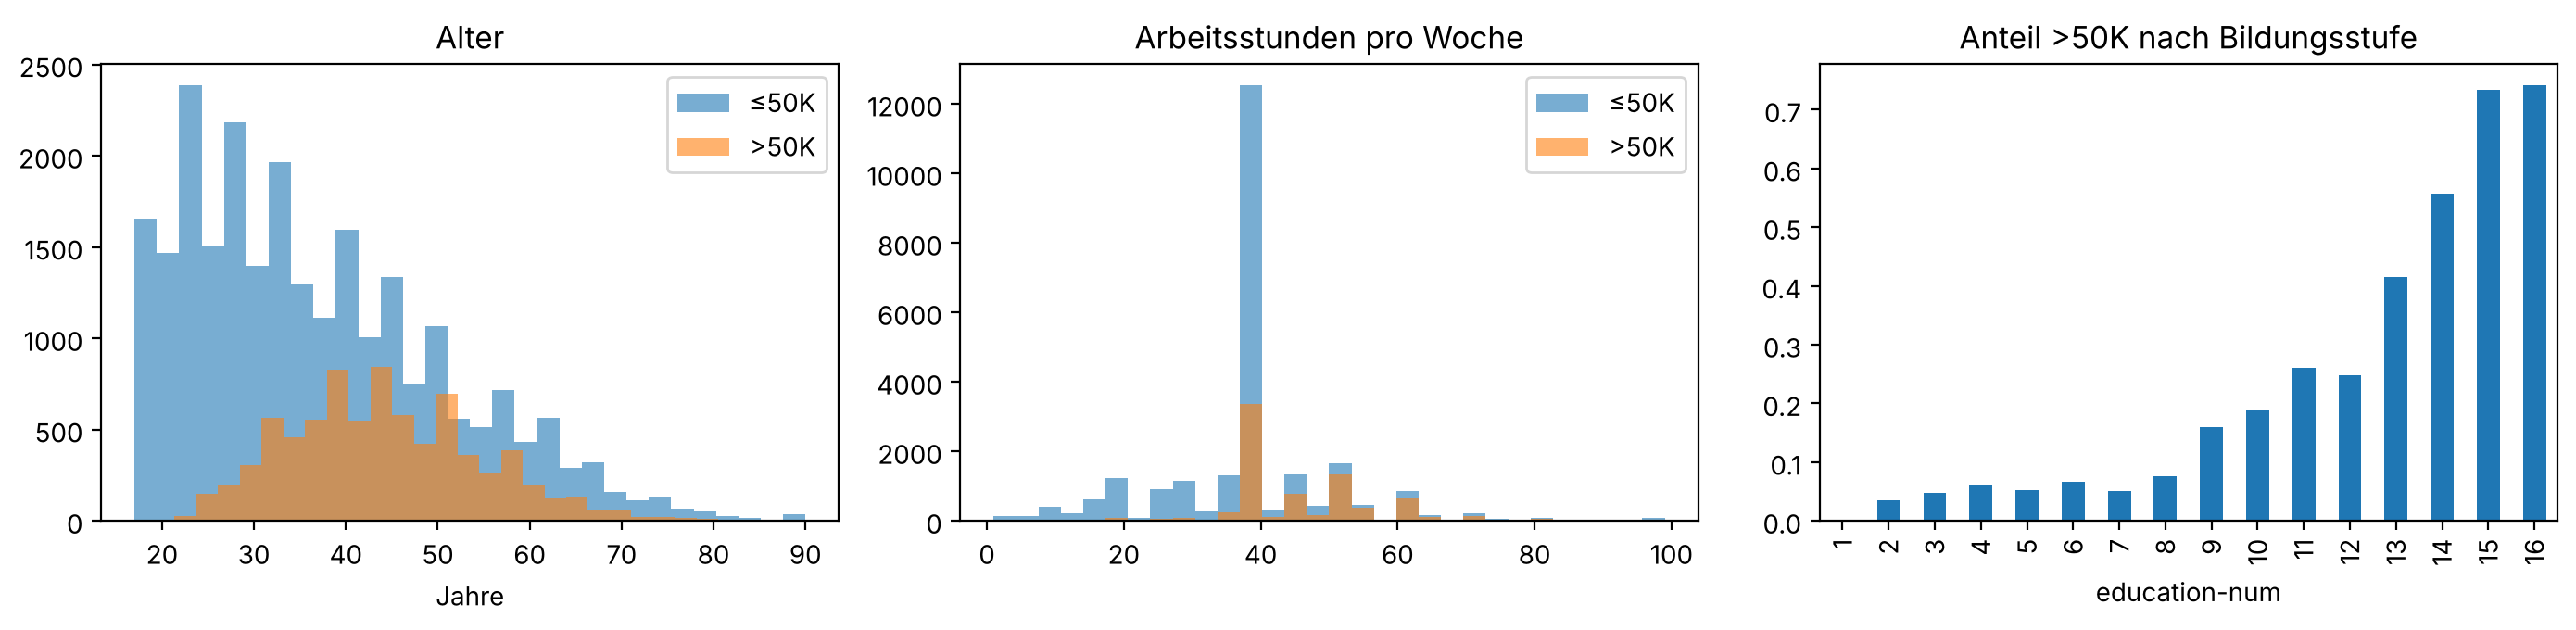

In [3]:
df_all = pd.concat([df_tr, df_va])
print("Fehlende Werte (Train+Val):")
print(df_all.isna().sum()[lambda s: s > 0])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for lbl, name in [(0, "≤50K"), (1, ">50K")]:
    ax[0].hist(df_all.loc[df_all[TARGET] == lbl, "age"], bins=30, alpha=0.6, label=name)
ax[0].set(title="Alter", xlabel="Jahre"); ax[0].legend()
for lbl, name in [(0, "≤50K"), (1, ">50K")]:
    ax[1].hist(df_all.loc[df_all[TARGET] == lbl, "hours-per-week"], bins=30, alpha=0.6, label=name)
ax[1].set(title="Arbeitsstunden pro Woche"); ax[1].legend()
df_all.groupby("education-num")[TARGET].mean().plot.bar(ax=ax[2], color="tab:blue")
ax[2].set(title="Anteil >50K nach Bildungsstufe", xlabel="education-num")
plt.tight_layout(); plt.show()

### Vorverarbeitung
- fehlende Werte (`?` in workclass, occupation, native-country) → häufigste Kategorie
- `education` entfernt (redundant zu `education-num`)
- `capital-gain`/`capital-loss` log1p-transformiert (stark schief)
- numerische Merkmale standardisiert, kategoriale One-Hot-codiert
- Preprocessor nur auf dem Train-Anteil gefittet

**Annahme für FL:** Alle Clients verwenden dasselbe Feature-Schema (Kategorien, Skalierung). In der Praxis müsste das vorab vereinbart oder föderiert berechnet werden.

In [4]:
X_tr, y_tr = d["X_train"], d["y_train"]
X_va, y_va = d["X_val"], d["y_val"]
X_te, y_te = d["X_test"], d["y_test"]
print("X_train", X_tr.shape, " X_val", X_va.shape, " X_test", X_te.shape)

X_train (27676, 89)  X_val (4885, 89)  X_test (16281, 89)


## 2. Modell

Multilayer Perceptron: 89 Eingänge → 64 → 32 → 1, ReLU, Dropout 0.1, Ausgabe als Logit (Sigmoid in der Loss-Funktion), Adam, binäre Kreuzentropie, Batchgröße 64.

Das Modell besteht nur aus Gewichtsmatrizen. Deshalb lassen sich FedAvg, FedProx, FedAvgM und FedMedian direkt anwenden.

In [5]:
model = MLP(in_dim=X_tr.shape[1])
print(model)
print("Parameter:", n_params(model))

MLP(
  (net): Sequential(
    (0): Linear(in_features=89, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parameter: 7873


## 3. Zentrale Baseline

Training mit Early Stopping auf dem Validierungs-Loss (max. 50 Epochen, Patience 5), drei Seeds.

In [6]:
central_runs, histories = [], {}
for s in SEEDS:
    m, hist = fit(X_tr, y_tr, X_va, y_va, max_epochs=50, patience=5, lr=1e-3, batch_size=64, seed=s)
    r = evaluate(m, X_te, y_te) | {"seed": s, "epochs": len(hist)}
    central_runs.append(r); histories[s] = hist
    print(f"Seed {s}: {len(hist)} Epochen, Test-Acc {r['accuracy']:.4f}, F1 {r['f1']:.4f}, AUC {r['roc_auc']:.4f}")

central = pd.DataFrame(central_runs)
metrics = ["accuracy", "balanced_acc", "f1", "roc_auc"]
central[metrics].agg(["mean", "std"]).round(4)

Seed 42: 23 Epochen, Test-Acc 0.8544, F1 0.6615, AUC 0.9065


Seed 43: 22 Epochen, Test-Acc 0.8565, F1 0.6638, AUC 0.9072


Seed 44: 21 Epochen, Test-Acc 0.8538, F1 0.6586, AUC 0.9066


,accuracy,balanced_acc,f1,roc_auc
mean,0.8549,0.7668,0.6613,0.9068
std,0.0014,0.0014,0.0026,0.0004


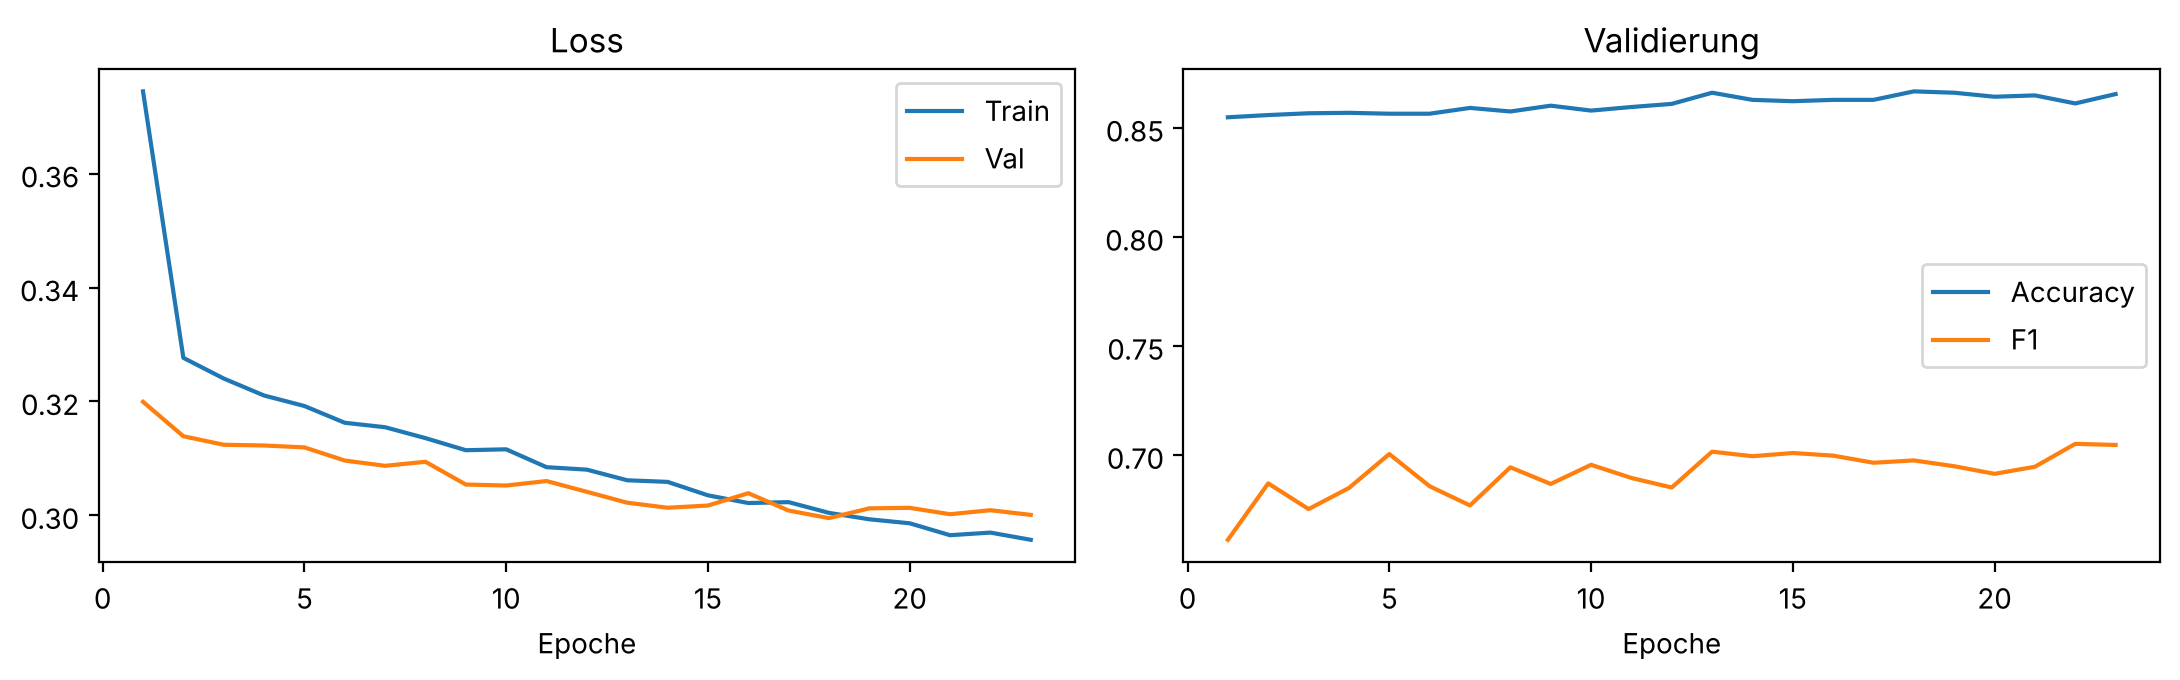

In [7]:
h = pd.DataFrame(histories[SEED])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss, label="Train"); ax[0].plot(h.epoch, h.val_loss, label="Val")
ax[0].set(title="Loss", xlabel="Epoche"); ax[0].legend()
ax[1].plot(h.epoch, h.val_accuracy, label="Accuracy"); ax[1].plot(h.epoch, h.val_f1, label="F1")
ax[1].set(title="Validierung", xlabel="Epoche"); ax[1].legend()
plt.tight_layout(); plt.savefig(RESULTS / "01_central_learning_curve.png", dpi=150); plt.show()

### Einordnung
Zum Vergleich zwei klassische Modelle mit derselben Vorverarbeitung: logistische Regression (lineares Modell) und Gradient Boosting (stärkstes Modell auf Tabellendaten, aber nicht föderierbar per Mittelwertbildung, daher nur Referenz).

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

def sk_eval(clf):
    p = clf.predict_proba(X_te)[:, 1]; yhat = (p >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y_te, yhat), "balanced_acc": balanced_accuracy_score(y_te, yhat),
            "f1": f1_score(y_te, yhat), "roc_auc": roc_auc_score(y_te, p)}

reference = {
    "MLP (unser Modell)": central[metrics].mean().to_dict(),
    "Logistische Regression": sk_eval(LogisticRegression(max_iter=2000).fit(X_tr, y_tr)),
    "Gradient Boosting (Referenz)": sk_eval(HistGradientBoostingClassifier(random_state=SEED).fit(X_tr, y_tr)),
    "Immer ≤50K": {"accuracy": 1 - y_te.mean(), "balanced_acc": 0.5, "f1": 0.0, "roc_auc": 0.5},
}
pd.DataFrame(reference).T.round(4)

,accuracy,balanced_acc,f1,roc_auc
MLP (unser Modell),0.8549,0.7668,0.6613,0.9068
Logistische Regression,0.8457,0.7557,0.6418,0.8973
Gradient Boosting (Referenz),0.8725,0.7964,0.7073,0.9249
Immer ≤50K,0.7638,0.5000,0.0000,0.5000


## 4. Lokale Baselines

Die Trainingsdaten werden genau so auf Clients verteilt wie später im FL-Experiment. Jeder Client trainiert ein eigenes MLP nur mit seinen Daten (85 % Training, 15 % lokale Validierung für Early Stopping). Jedes Modell wird auf dem gemeinsamen Testset ausgewertet; angegeben wird Mittelwert ± Std über die Clients.

Partitionierungen:
- **IID** mit 2, 5, 10, 20 Clients (stratifiziert, gleich groß)
- **Label-Skew** mit 10 Clients, Dirichlet α = 1.0 / 0.5 / 0.1 (kleiner = stärker non-IID)
- **Feature-Skew**: 5 Clients nach Altersgruppen (Quintile)

In [9]:
partitions = {
    **{f"IID, {k} Clients": iid_partition(y_tr, k, seed=SEED) for k in (2, 5, 10, 20)},
    **{f"Dirichlet α={a}, 10 Clients": dirichlet_partition(y_tr, 10, alpha=a, seed=SEED) for a in (1.0, 0.5, 0.1)},
    "Alter, 5 Clients": attribute_partition(df_tr, "age", 5, seed=SEED),
}
for name in ["Dirichlet α=0.1, 10 Clients", "Alter, 5 Clients"]:
    print(name); print(describe(partitions[name], y_tr).round(3).to_string(index=False)); print()

Dirichlet α=0.1, 10 Clients
 client     n  pos_rate
      0  1600     1.000
      1  4046     0.000
      2 12035     0.000
      3  3714     1.000
      4   244     1.000
      5  1841     0.002
      6   122     1.000
      7  2953     0.000
      8    69     1.000
      9  1052     0.865

Alter, 5 Clients
 client    n  pos_rate
      0 6104     0.026
      1 5067     0.177
      2 5723     0.310
      3 5325     0.389
      4 5457     0.323



In [10]:
def local_baseline(parts, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for cid, idx in enumerate(parts):
        idx = rng.permutation(idx)
        n_val = max(int(0.15 * len(idx)), 1)
        val_idx, tr_idx = idx[:n_val], idx[n_val:]
        m, hist = fit(X_tr[tr_idx], y_tr[tr_idx], X_tr[val_idx], y_tr[val_idx],
                      max_epochs=50, patience=5, seed=seed)
        rows.append(evaluate(m, X_te, y_te) | {"client": cid, "n": len(idx),
                                               "pos_rate": y_tr[idx].mean(), "epochs": len(hist)})
    return pd.DataFrame(rows)

local_runs = {}
for name, parts in partitions.items():
    local_runs[name] = local_baseline(parts)
    r = local_runs[name]
    print(f"{name:30s} Acc {r.accuracy.mean():.4f} ± {r.accuracy.std():.4f}   F1 {r.f1.mean():.4f} ± {r.f1.std():.4f}")

IID, 2 Clients                 Acc 0.8514 ± 0.0005   F1 0.6551 ± 0.0060


IID, 5 Clients                 Acc 0.8465 ± 0.0023   F1 0.6538 ± 0.0085


IID, 10 Clients                Acc 0.8445 ± 0.0017   F1 0.6460 ± 0.0113


IID, 20 Clients                Acc 0.8398 ± 0.0037   F1 0.6401 ± 0.0116


Dirichlet α=1.0, 10 Clients    Acc 0.7483 ± 0.1034   F1 0.4611 ± 0.2554


Dirichlet α=0.5, 10 Clients    Acc 0.8118 ± 0.0307   F1 0.4727 ± 0.2742


Dirichlet α=0.1, 10 Clients    Acc 0.4854 ± 0.2662   F1 0.2457 ± 0.2173


Alter, 5 Clients               Acc 0.8251 ± 0.0194   F1 0.5865 ± 0.1367


## 5. Zusammenfassung

In [11]:
rows = [{"Setting": "Zentral (alle Daten)", **{f"{m}": central[m].mean() for m in metrics},
         **{f"{m}_std": central[m].std() for m in metrics}}]
for name, r in local_runs.items():
    rows.append({"Setting": f"Lokal – {name}", **{m: r[m].mean() for m in metrics},
                 **{f"{m}_std": r[m].std() for m in metrics}})
summary = pd.DataFrame(rows).set_index("Setting")
summary[metrics].round(4)

,accuracy,balanced_acc,f1,roc_auc
Setting,,,,
Zentral (alle Daten),0.8549,0.7668,0.6613,0.9068
"Lokal – IID, 2 Clients",0.8514,0.7637,0.6551,0.9026
"Lokal – IID, 5 Clients",0.8465,0.7662,0.6538,0.8997
"Lokal – IID, 10 Clients",0.8445,0.7606,0.6460,0.8972
"Lokal – IID, 20 Clients",0.8398,0.7583,0.6401,0.8931
"Lokal – Dirichlet α=1.0, 10 Clients",0.7483,0.6935,0.4611,0.8849
"Lokal – Dirichlet α=0.5, 10 Clients",0.8118,0.6939,0.4727,0.8831
"Lokal – Dirichlet α=0.1, 10 Clients",0.4854,0.5241,0.2457,0.8047
"Lokal – Alter, 5 Clients",0.8251,0.7376,0.5865,0.8866


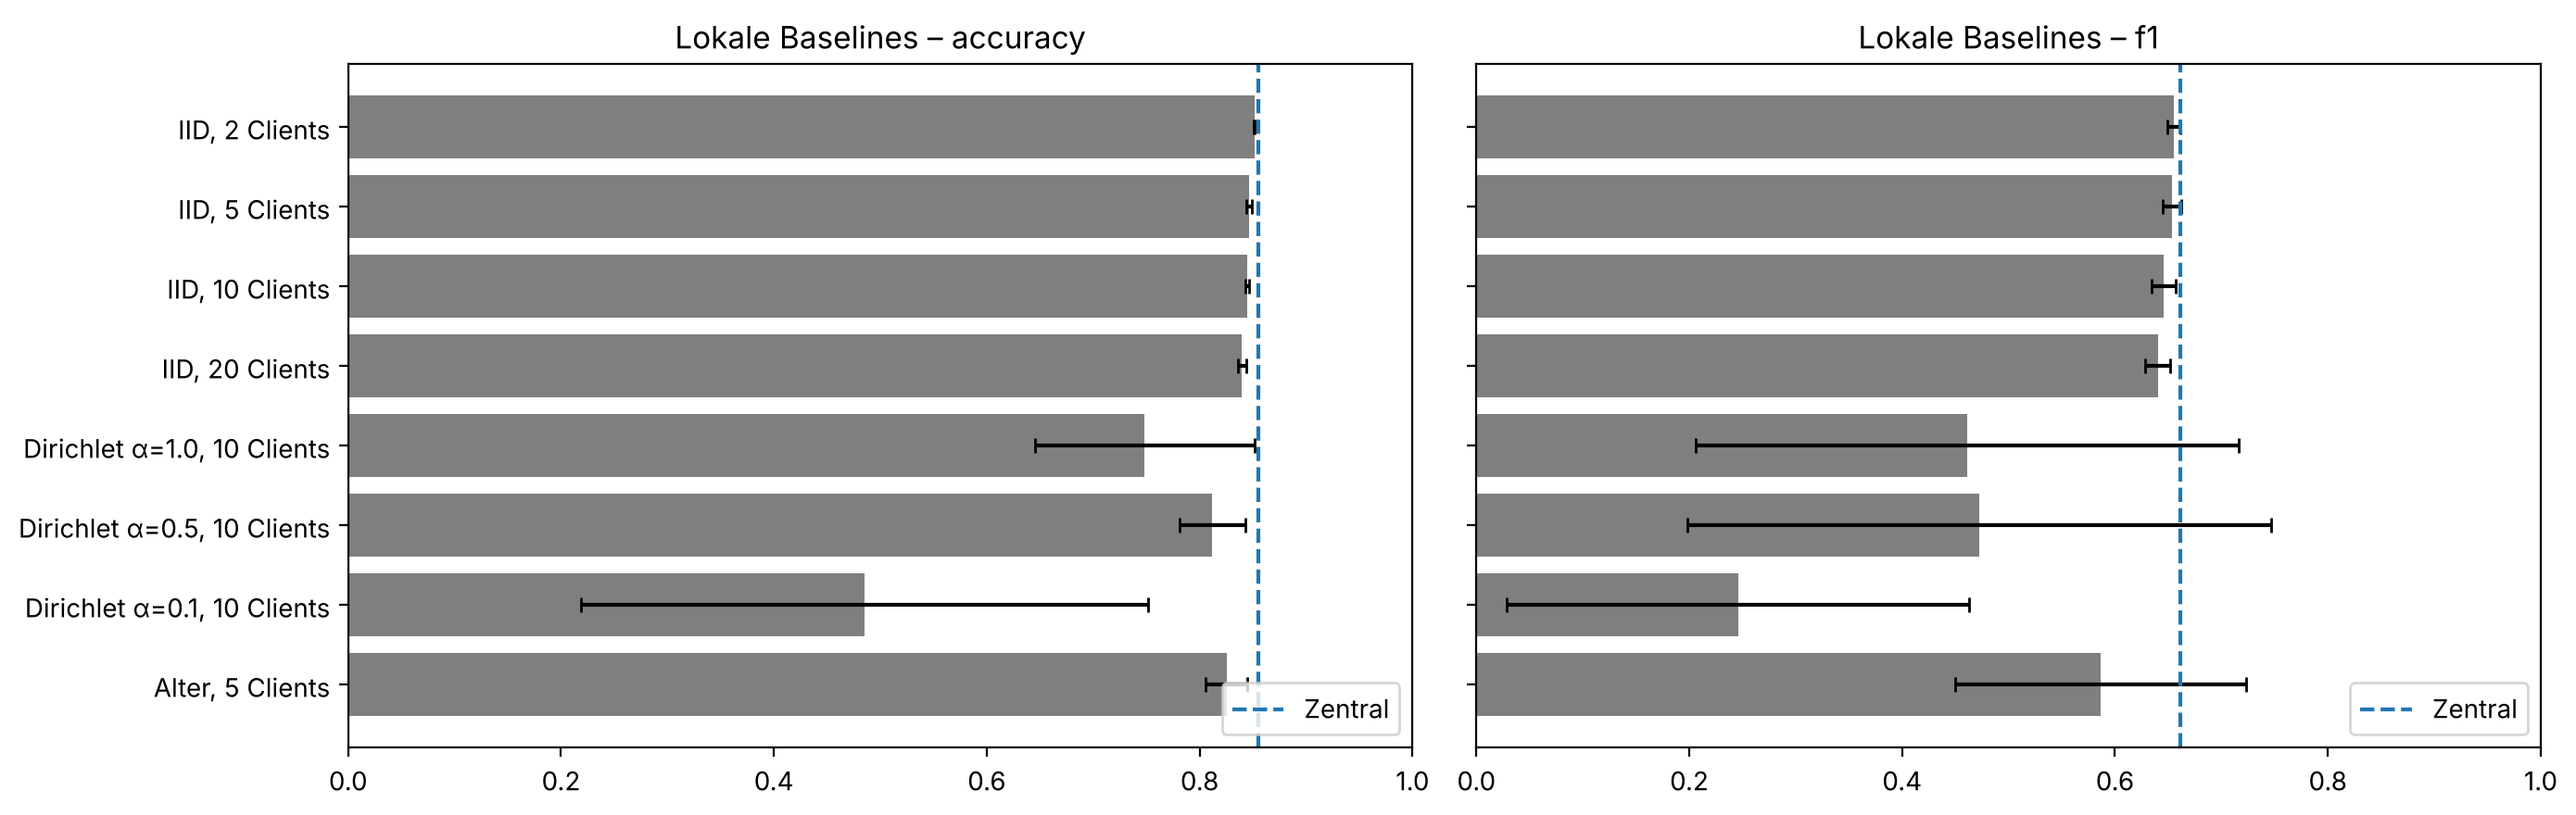

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, m in zip(ax, ["accuracy", "f1"]):
    s = summary.iloc[1:]
    a.barh(s.index.str.replace("Lokal – ", ""), s[m], xerr=s[f"{m}_std"], color="tab:gray", capsize=3)
    a.axvline(summary.loc["Zentral (alle Daten)", m], color="tab:blue", ls="--", label="Zentral")
    a.set(title=f"Lokale Baselines – {m}", xlim=(0, 1)); a.legend(loc="lower right")
ax[0].invert_yaxis()
plt.tight_layout(); plt.savefig(RESULTS / "01_local_vs_central.png", dpi=150); plt.show()

In [13]:
out = {
    "central": {"runs": central_runs, "mean": central[metrics].mean().to_dict(), "std": central[metrics].std().to_dict()},
    "reference": reference,
    "local": {name: {"mean": r[metrics].mean().to_dict(), "std": r[metrics].std().to_dict(),
                     "clients": r.to_dict(orient="records")} for name, r in local_runs.items()},
    "config": {"seeds": SEEDS, "val_size": 0.15, "hidden": [64, 32], "dropout": 0.1,
               "lr": 1e-3, "batch_size": 64, "max_epochs": 50, "patience": 5},
}
(RESULTS / "01_baselines.json").write_text(json.dumps(out, indent=2, default=float))
print("gespeichert:", RESULTS / "01_baselines.json")

gespeichert: results/01_baselines.json


## Beobachtungen

- Das MLP erreicht zentral etwa das Niveau aus der Literatur für neuronale Netze auf Adult und liegt knapp über der logistischen Regression.
- **IID:** Lokale Modelle sind fast so gut wie das zentrale – Adult ist groß genug, dass auch ein Zwanzigstel der Daten reicht. Für FL bleibt bei IID wenig zu gewinnen.
- **Label-Skew:** Die lokalen Modelle brechen ein und streuen stark. Clients mit fast nur „≤50K“ lernen „immer ≤50K“ (F1 = 0), Clients mit überwiegend „>50K“ sagen zu oft >50K voraus. Bei α = 0.1 liegt die mittlere Accuracy unter der des trivialen Modells. Hier muss FL zeigen, was es bringt (Task 3 und 4).
- α = 1.0 schneidet hier schlechter ab als α = 0.5. Das liegt an der einzelnen Zufallsziehung der Partition (bei α = 1.0 haben zwei Clients 84–92 % >50K). Für Task 3 deshalb die Partitionierung mit mehreren Seeds wiederholen.
- **Alter:** Der Client mit den jüngsten Personen (2,6 % >50K) erreicht nur F1 ≈ 0.34, die anderen ≈ 0.63–0.66.